In [48]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import mplfinance as mpf

In [49]:
crypto = pd.read_csv('/Users/jonas/Documents/GitHub/ZHAW/Semester 5/MLDM/Hackathon/data/crypto_time_series.csv')

# separate after "coin"
df = crypto[crypto['coin'] == 'BTC'].copy()
df

,date,open,high,low,close,volume,market_cap,coin
0,2018-08-14,6287.66,6287.94,5971.05,6199.71,5.301700e+09,1.081991e+11,BTC
1,2018-08-13,6341.36,6537.05,6225.72,6297.57,4.083980e+09,1.091115e+11,BTC
2,2018-08-12,6283.65,6409.85,6237.50,6322.69,5.665250e+09,1.081065e+11,BTC
3,2018-08-11,6185.79,6455.74,6109.03,6295.73,4.047850e+09,1.064095e+11,BTC
4,2018-08-10,6571.42,6591.26,6124.52,6184.71,4.528680e+09,1.130288e+11,BTC
...,...,...,...,...,...,...,...,...
1930,2013-05-02,116.38,125.60,92.28,105.21,NaN,1.292190e+09,BTC
1931,2013-05-01,139.00,139.89,107.72,116.99,NaN,1.542820e+09,BTC
1932,2013-04-30,144.00,146.93,134.05,139.00,NaN,1.597780e+09,BTC
1933,2013-04-29,134.44,147.49,134.00,144.54,NaN,1.491160e+09,BTC


In [50]:
# Beispiel: df ist schon geladen und nach Datum sortiert
# df.columns = ["date", "open", "high", "low", "close", "volume", "market_cap", "coin"]

df["date"] = pd.to_datetime(df["date"])
df.dropna(inplace=True)
df = df.sort_values("date").reset_index(drop=True)

k = 14  # Fenster-Haelfte: k Tage links, k Tage rechts

# Lokale Tops
def is_local_top(window):
    center_idx = len(window) // 2
    return 1.0 if window.iloc[center_idx] == window.max() else 0.0

# Lokale Bottoms
def is_local_bottom(window):
    center_idx = len(window) // 2
    return 1.0 if window.iloc[center_idx] == window.min() else 0.0

window_size = 2 * k + 1

df["is_top"] = (
    df["high"]
    .rolling(window=window_size, center=True)
    .apply(is_local_top, raw=False)
)

df["is_bottom"] = (
    df["low"]
    .rolling(window=window_size, center=True)
    .apply(is_local_bottom, raw=False)
)

# Rander werden NaN, weil nicht genug linke/rechte Nachbarn vorhanden:
df = df.dropna(subset=["is_top", "is_bottom"])

# In int umwandeln
df["is_top"] = df["is_top"].astype(int)
df["is_bottom"] = df["is_bottom"].astype(int)

In [51]:
df["return_1d"] = df["close"].pct_change()
df["return_3d"] = df["close"].pct_change(3)
df["volatility_7d"] = df["return_1d"].rolling(7).std()
df["high_low_range"] = (df["high"] - df["low"]) / df["close"]
df["volume_log"] = np.log1p(df["volume"])

feature_cols = [
    "return_1d",
    "return_3d",
    "volatility_7d",
    "high_low_range",
    "volume_log",
]

df = df.dropna(subset=feature_cols + ["is_top", "is_bottom"])

In [52]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report

X = df[feature_cols]
y_bottom = df["is_bottom"]

# Zeitbasierter Split (z.B. 80% train, 20% test)
split_idx = int(0.8 * len(df))
X_train, X_test = X.iloc[:split_idx], X.iloc[split_idx:]
y_train, y_test = y_bottom.iloc[:split_idx], y_bottom.iloc[split_idx:]

clf = RandomForestClassifier(
    n_estimators=200,
    max_depth=6,
    random_state=42,
    class_weight="balanced"  # weil Tops/Bottoms vermutlich selten sind
)
clf.fit(X_train, y_train)

y_pred = clf.predict(X_test)
print(classification_report(y_test, y_pred, digits=3))

              precision    recall  f1-score   support

           0      0.983     1.000     0.992       292
           1      0.000     0.000     0.000         5

    accuracy                          0.983       297
   macro avg      0.492     0.500     0.496       297
weighted avg      0.967     0.983     0.975       297



/Users/jonas/miniconda3/envs/MLDM/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/jonas/miniconda3/envs/MLDM/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/jonas/miniconda3/envs/MLDM/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capi

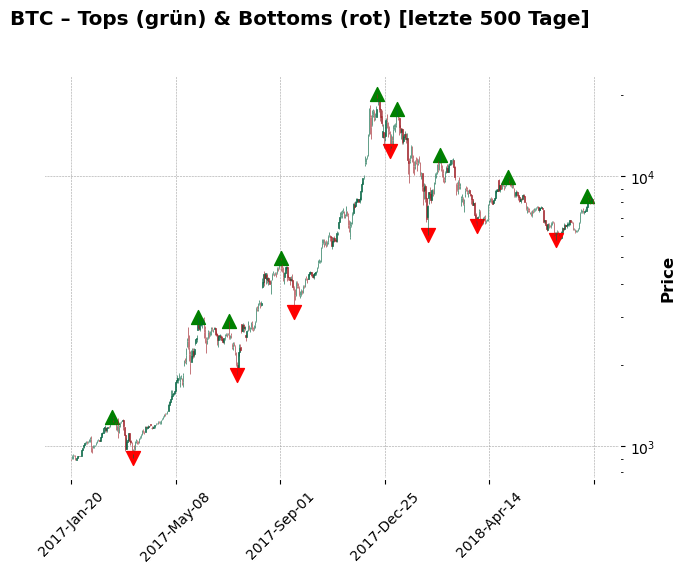

In [53]:
# df_plot vorbereiten
df_plot = df.copy()
df_plot["date"] = pd.to_datetime(df_plot["date"])
df_plot = df_plot.sort_values("date").set_index("date")
df_plot = df_plot[["open", "high", "low", "close", "volume"]]

# Nur die letzten x Tage plotten
graph_length = 500
df_plot_subset = df_plot.tail(graph_length)

# Tops und Bottoms NEU aus dem Subset extrahieren
tops_subset = df[df["is_top"] == 1].tail(100).set_index("date")
tops_subset = tops_subset[tops_subset.index.isin(df_plot_subset.index)]

bottoms_subset = df[df["is_bottom"] == 1].tail(100).set_index("date")
bottoms_subset = bottoms_subset[bottoms_subset.index.isin(df_plot_subset.index)]

# WICHTIG: Reindex auf df_plot_subset, damit Längen passen
add_plots = []
if not tops_subset.empty:
    tops_aligned = tops_subset["high"].reindex(df_plot_subset.index)
    add_plots.append(
        mpf.make_addplot(tops_aligned, type="scatter", marker="^",
                        markersize=100, color="green")
    )

if not bottoms_subset.empty:
    bottoms_aligned = bottoms_subset["low"].reindex(df_plot_subset.index)
    add_plots.append(
        mpf.make_addplot(bottoms_aligned, type="scatter", marker="v",
                        markersize=100, color="red")
    )

mpf.plot(df_plot_subset, type="candle", style="charles", addplot=add_plots,
         volume=False, title=f"BTC – Tops (grün) & Bottoms (rot) [letzte {graph_length} Tage]", yscale="log")

# Model